# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [4]:

import pandas as pd

# 1. Загружаем набор данных
df = pd.read_csv("Orange_Telecom_Churn_Data.csv")

# 2. Указываем удалённые и оставшиеся категориальные столбцы
removed_cols = ["state", "area_code", "phone_number"]

# Категориальные столбцы, которые остались в наборе данных
remaining_cat_cols = [
    col for col in df.columns
    if col not in removed_cols
    and (
        df[col].dtype == "object"
        or df[col].dtype == "bool"
        or col == "area_code"
    )
]

# 3. Объединяем списки для анализа
cat_cols = removed_cols + remaining_cat_cols

# 4. Считаем уникальные значения в каждом столбце
results = []

for col in cat_cols:
    results.append({
        "Column": col,
        "Type": "Removed" if col in removed_cols else "Remaining",
        "Unique_values": df[col].nunique(dropna=False),
        "Missing_values": df[col].isna().sum()
    })

# 5. Создаём таблицу результатов
cardinality = pd.DataFrame(results)
cardinality = cardinality.sort_values(
    by="Unique_values", ascending=False
)

print(cardinality.to_string(index=False))

### Применение OneHotEncoder или LabelBinarizer к признаку phone_number значительно увеличило бы размерность данных
# поскольку каждому уникальному номеру соответствовал бы отдельный бинарный признак. Для алгоритма KNN это приводит к росту вычислительных затрат и может ухудшить качество поиска ближайших соседей.
# расстояние между различными one-hot представлениями номеров одинаково и не отражает сходство поведения клиентов. Большое количество неинформативных признаков повышает риск переобучения
# и ухудшает способность модели обобщать закономерности на новых данных.
###


      Column      Type  Unique_values  Missing_values
phone_number   Removed           5000               0
       state   Removed             51               0
   area_code   Removed              3               0
     churned Remaining              2               0


### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [1]:

import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Данные двух клиентов: account_length и total_day_charge
X = np.array([
    [100, 20],  # Клиент A
    [150, 50]   # Клиент B
])

# Расстояние без масштабирования
distance_original = np.linalg.norm(X[0] - X[1])

# Границы признаков из условия
scaler = MinMaxScaler()
scaler.fit([
    [1, 0],
    [250, 100]
])

# Масштабируем данные
X_scaled = scaler.transform(X)

# Расстояние после масштабирования
distance_scaled = np.linalg.norm(
    X_scaled[0] - X_scaled[1]
)

print("Исходные данные:")
print(X)

print("\nМасштабированные данные:")
print(X_scaled.round(4))

print("\nРасстояние без масштабирования:",
      round(distance_original, 4))

print("Расстояние после MinMaxScaler:",
      round(distance_scaled, 4))

###### StandardScaler преобразует признаки с использованием среднего значения и стандартного отклонения. При наличии выбросов эти
###### статистики могут существенно изменяться, что влияет на масштабирование обычных наблюдений. 


Исходные данные:
[[100  20]
 [150  50]]

Масштабированные данные:
[[0.3976 0.2   ]
 [0.5984 0.5   ]]

Расстояние без масштабирования: 58.3095
Расстояние после MinMaxScaler: 0.361


### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [5]:

import timeit
import numpy as np

# Импортируем обычную реализацию ДО применения патча
from sklearn.neighbors import KNeighborsClassifier as KNN_original

# Создаём одинаковые данные для обоих тестов
rng = np.random.default_rng(42)
X = rng.random((100_000, 10))
y = rng.integers(0, 2, size=100_000)

# Функция одного запуска обычного обучения
def fit_original():
    model = KNN_original(n_neighbors=5, algorithm="auto")
    model.fit(X, y)

# Измеряем время без патча
times_original = timeit.repeat(
    stmt=fit_original,
    repeat=3,
    number=1
)

# Применяем патч Intel
from sklearnex import patch_sklearn
patch_sklearn()

# Повторно импортируем класс после патча
from sklearn.neighbors import KNeighborsClassifier as KNN_patched

# Функция одного запуска обучения после патча
def fit_patched():
    model = KNN_patched(n_neighbors=5, algorithm="auto")
    model.fit(X, y)

# Измеряем время с патчем
times_patched = timeit.repeat(
    stmt=fit_patched,
    repeat=3,
    number=1
)

# Выводим результаты
print("Без патча (секунды):", np.round(times_original, 4))
print("С патчем (секунды):", np.round(times_patched, 4))

print("Среднее без патча:", round(np.mean(times_original), 4))
print("Среднее с патчем:", round(np.mean(times_patched), 4))

speedup = np.mean(times_original) / np.mean(times_patched)
print("Отношение времени (без / с патчем):", round(speedup, 3))

###### Функция patch_sklearn() заменяет поддерживаемые реализации scikit-learn оптимизированными версиями, которые могут использовать векторизацию процессора, эффективные математические операции и параллельные вычисления.


Без патча (секунды): [0.0442 0.0445 0.043 ]
С патчем (секунды): [0.0448 0.0433 0.0472]
Среднее без патча: 0.0439
Среднее с патчем: 0.0451
Отношение времени (без / с патчем): 0.973


Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

p=1: Accuracy=0.920
p=2: Accuracy=0.920
p=10: Accuracy=0.907
Вычисляем границу для p=1...
Вычисляем границу для p=2...
Вычисляем границу для p=10...


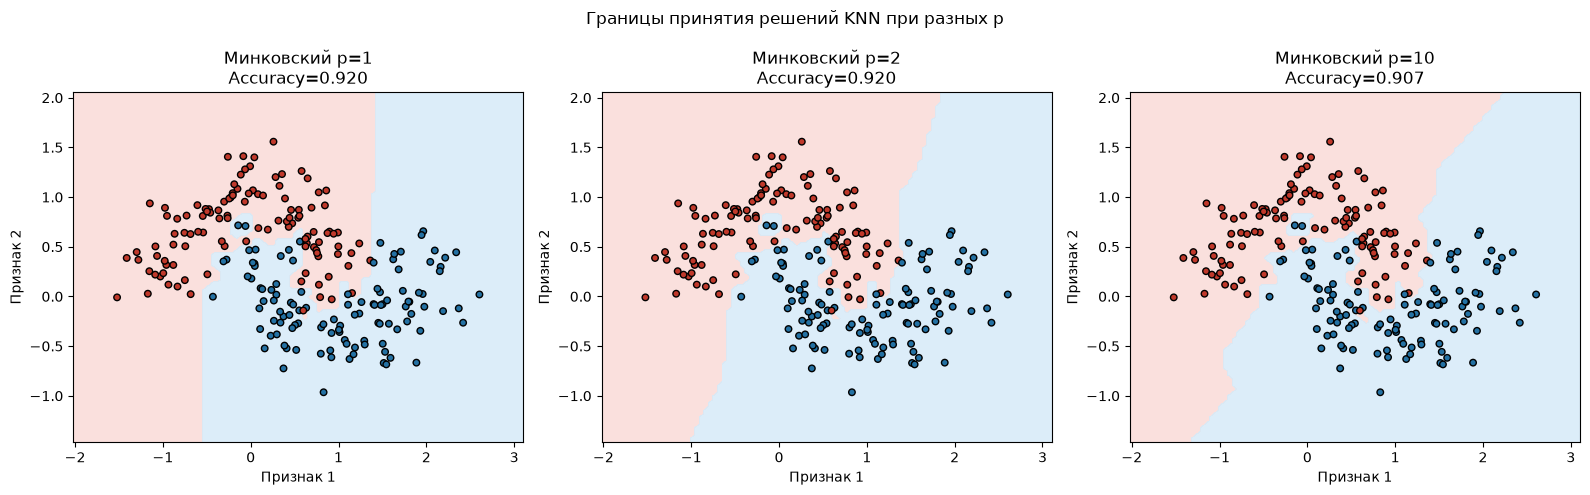

In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from matplotlib.colors import ListedColormap
from sklearn.metrics import accuracy_score

# 1. Собственная функция расстояния Минковского
def minkowski_distance(x, y, p):
    x = np.asarray(x)
    y = np.asarray(y)

    if p < 1:
        raise ValueError("p должен быть >= 1")

    return np.sum(np.abs(x - y) ** p) ** (1 / p)


# 2. Создаём данные
X, y = make_moons(
    n_samples=300,
    noise=0.22,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


# 3. Быстрый KNN с собственной метрикой Минковского
# Расстояния вычисляются сразу для группы точек,
# а не по одной точке в медленном цикле Python.
def custom_knn_predict(X_train, y_train, X_query, p, batch_size=500):
    X_train = np.asarray(X_train, dtype=float)
    X_query = np.asarray(X_query, dtype=float)
    y_train = np.asarray(y_train)

    predictions = []

    for start in range(0, len(X_query), batch_size):
        batch = X_query[start:start + batch_size]

        # Размер массива: точки запроса × обучающие точки × признаки
        differences = (
            batch[:, np.newaxis, :] -
            X_train[np.newaxis, :, :]
        )

        distances = np.sum(
            np.abs(differences) ** p,
            axis=2
        ) ** (1 / p)

        nearest_indices = np.argmin(distances, axis=1)
        predictions.extend(y_train[nearest_indices])

    return np.asarray(predictions)


# 4. Проверяем точность для разных p
p_values = [1, 2, 10]
accuracies = {}

for p in p_values:
    predictions = custom_knn_predict(
        X_train, y_train, X_test, p
    )

    accuracies[p] = accuracy_score(y_test, predictions)
    print(f"p={p}: Accuracy={accuracies[p]:.3f}")


# 5. Готовим сетку для границ принятия решений
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

# 100 × 100 вместо 180 × 180
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 100),
    np.linspace(y_min, y_max, 100)
)

grid_points = np.column_stack((xx.ravel(), yy.ravel()))

background_cmap = ListedColormap(["#FADBD8", "#D6EAF8"])
points_cmap = ListedColormap(["#C0392B", "#2471A3"])


# 6. Вычисляем предсказания для сетки
# Сначала завершаем вычисления, потом рисуем графики.
grid_results = {}

for p in p_values:
    print(f"Вычисляем границу для p={p}...")

    grid_predictions = custom_knn_predict(
        X_train, y_train, grid_points, p
    )

    grid_results[p] = grid_predictions.reshape(xx.shape)


# 7. Строим все три графика
plt.close("all")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, p in zip(axes, p_values):
    ax.contourf(
        xx, yy, grid_results[p],
        levels=[-0.5, 0.5, 1.5],
        cmap=background_cmap,
        alpha=0.85
    )

    ax.scatter(
        X_train[:, 0],
        X_train[:, 1],
        c=y_train,
        cmap=points_cmap,
        edgecolors="black",
        s=22
    )

    ax.set_title(
        f"Минковский p={p}\nAccuracy={accuracies[p]:.3f}"
    )
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")

plt.suptitle("Границы принятия решений KNN при разных p")
plt.tight_layout()
plt.show()


### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [3]:
# При K=1 на обучающей выборке ближайшим соседом точки может быть она сама, а расстояние до неё равно нулю. Поэтому модель возвращает её собственный класс и получает 100% точности.
# Это не означает, что модель хорошо работает на новых данных: она могла запомнить обучающие объекты, поэтому качество нужно проверять на отдельной тестовой выборке#

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [15]:

import pandas as pd
import numpy as np

class CustomKNN:
    def __init__(self):
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        # Сохраняем обучающие данные
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)

        if self.X_train.ndim != 2:
            raise ValueError("X должен быть двумерной матрицей")

        if len(self.X_train) != len(self.y_train):
            raise ValueError("Количество объектов и меток должно совпадать")

        return self

    def predict(self, X_test, k=3):
        if self.X_train is None:
            raise ValueError("Сначала вызовите fit()")

        X_test = np.asarray(X_test, dtype=float)

        if X_test.ndim == 1:
            X_test = X_test.reshape(1, -1)

        if X_test.shape[1] != self.X_train.shape[1]:
            raise ValueError("Число признаков должно совпадать")

        if not isinstance(k, (int, np.integer)) or k < 1:
            raise ValueError("k должно быть положительным целым числом")

        if k > len(self.X_train):
            raise ValueError("k не может превышать размер обучающей выборки")

        predictions = []

        for x in X_test:
            # 1. Вычисляем евклидово расстояние до всех объектов
            distances = np.sqrt(
                np.sum((self.X_train - x) ** 2, axis=1)
            )

            # 2. Находим индексы k ближайших соседей
            nearest_indices = np.argsort(distances)[:k]

            # 3. Получаем классы ближайших соседей
            nearest_labels = self.y_train[nearest_indices]

            # 4. Голосование большинством
            labels, counts = np.unique(
                nearest_labels, return_counts=True
            )
            prediction = labels[np.argmax(counts)]

            predictions.append(prediction)

        return np.array(predictions)


df = pd.read_csv("Orange_Telecom_Churn_Data.csv")

# Целевая переменная
target_col = "churned"

# Преобразуем целевой класс в числа, если он текстовый
target = df[target_col]

if target.dtype == "object":
    target = target.astype(str).str.strip().str.lower()
    target = target.map({
        "true": 1, "false": 0,
        "yes": 1, "no": 0,
        "1": 1, "0": 0
    })
else:
    target = target.astype(int)

# Выбираем числовые признаки, исключая цель и area_code
excluded = [target_col, "area_code"]
feature_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in excluded
]

X_df = df[feature_cols].copy()
y = target.to_numpy()

# Удаляем строки, где не удалось определить целевой класс
valid = ~pd.isna(y)
X_df = X_df.loc[valid].reset_index(drop=True)
y = y[valid].astype(int)

# Заполняем пропуски медианой каждого признака
X_df = X_df.fillna(X_df.median())

X = X_df.to_numpy(dtype=float)

# Разделяем данные случайно: 80% обучение, 20% тест
rng = np.random.default_rng(42)
indices = rng.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Масштабируем по статистикам обучающей выборки
mins = X_train.min(axis=0)
ranges = X_train.max(axis=0) - mins
ranges[ranges == 0] = 1

X_train = (X_train - mins) / ranges
X_test = (X_test - mins) / ranges

# Обучаем и проверяем собственный KNN
model = CustomKNN()
model.fit(X_train, y_train)

predictions = model.predict(X_test, k=3)

accuracy = np.mean(predictions == y_test)

print("Количество признаков:", X_train.shape[1])
print("Обучающих объектов:", len(X_train))
print("Тестовых объектов:", len(X_test))
print(f"Точность на тесте: {accuracy:.3f}")


Количество признаков: 15
Обучающих объектов: 4000
Тестовых объектов: 1000
Точность на тесте: 0.889


### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

 K  Mean_Accuracy  Std_Accuracy  Validation_Error
 1         0.8732        0.0088            0.1268
 2         0.8898        0.0026            0.1102
 3         0.8992        0.0048            0.1008
 4         0.8916        0.0060            0.1084
 5         0.9016        0.0036            0.0984
 6         0.8910        0.0040            0.1090
 7         0.8978        0.0040            0.1022
 8         0.8922        0.0041            0.1078
 9         0.9012        0.0041            0.0988
10         0.8952        0.0039            0.1048
11         0.9012        0.0025            0.0988
12         0.8968        0.0033            0.1032
13         0.9014        0.0036            0.0986
14         0.8962        0.0031            0.1038
15         0.8998        0.0048            0.1002
16         0.8946        0.0035            0.1054
17         0.8996        0.0033            0.1004
18         0.8912        0.0028            0.1088
19         0.8954        0.0034            0.1046


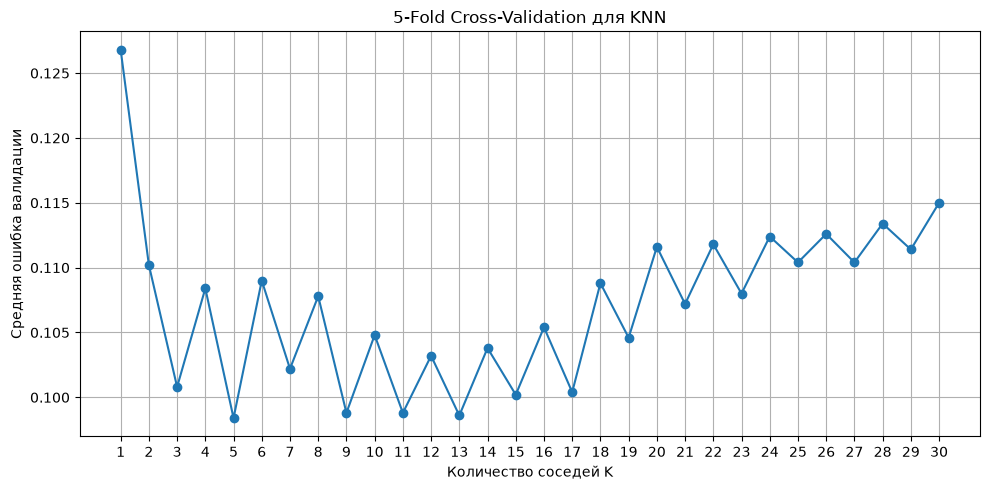

In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier

# 1. Загружаем данные
df = pd.read_csv("Orange_Telecom_Churn_Data.csv")

target_col = "churned"

# 2. Удаляем цель и идентификаторы из признаков
# state можно исключить, как в предыдущем упражнении
drop_cols = [
    target_col, "phone_number", "state", "area_code"
]
X = df.drop(columns=drop_cols, errors="ignore")
y = df[target_col]

# Если целевая переменная текстовая, кодируем её в 0 и 1
if y.dtype == "object":
    y = y.astype(str).str.strip().str.lower().map({
        "true": 1, "false": 0,
        "yes": 1, "no": 0,
        "1": 1, "0": 0
    })

# Удаляем строки с неизвестным целевым классом
valid = y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].astype(int).reset_index(drop=True)

# 3. Определяем типы признаков
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [
    col for col in X.columns if col not in numeric_cols
]

# 4. Предобработка числовых признаков
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

# 5. Предобработка категориальных признаков
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# 6. Настраиваем 5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# 7. Проверяем K от 1 до 30
for k in range(1, 31):
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    results.append({
        "K": k,
        "Mean_Accuracy": scores.mean(),
        "Std_Accuracy": scores.std(),
        "Validation_Error": 1 - scores.mean()
    })

# 8. Выводим результаты
results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

# 9. Определяем оптимальное K по минимальной ошибке
best_index = results_df["Validation_Error"].idxmin()
best_row = results_df.loc[best_index]

print("\nОптимальное K:", int(best_row["K"]))
print("Средняя точность:", round(best_row["Mean_Accuracy"], 4))
print("Стандартное отклонение:", round(best_row["Std_Accuracy"], 4))
print("Ошибка валидации:", round(best_row["Validation_Error"], 4))

# 10. Строим график ошибки
plt.figure(figsize=(10, 5))
plt.plot(
    results_df["K"],
    results_df["Validation_Error"],
    marker="o"
)
plt.xticks(range(1, 31))
plt.xlabel("Количество соседей K")
plt.ylabel("Средняя ошибка валидации")
plt.title("5-Fold Cross-Validation для KNN")
plt.grid(True)
plt.tight_layout()
plt.show()


### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

Количество объектов каждого класса:
churned
0    4293
1     707
Name: count, dtype: int64

Доли классов:
churned
0    0.859
1    0.141
Name: proportion, dtype: float64

Accuracy: 0.898
Precision для ушедших клиентов: 0.7407
Recall для ушедших клиентов: 0.4255
F1-score для ушедших клиентов: 0.5405

Отчёт по классификации:
              precision    recall  f1-score   support

 Остался (0)       0.91      0.98      0.94       859
    Ушёл (1)       0.74      0.43      0.54       141

    accuracy                           0.90      1000
   macro avg       0.83      0.70      0.74      1000
weighted avg       0.89      0.90      0.89      1000



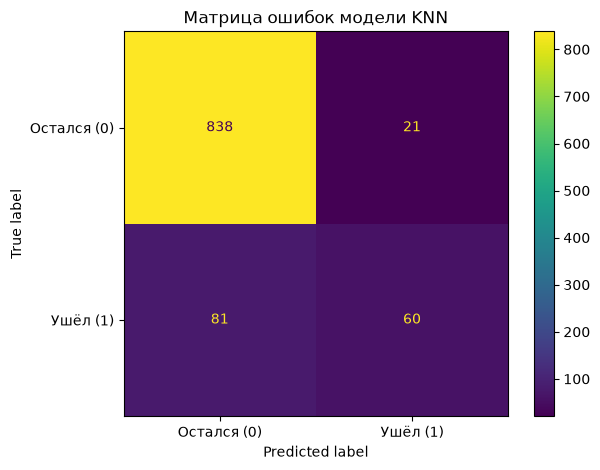

In [1]:
#При несбалансированных классах модель может всегда предсказывать, что клиент не уйдёт, и при этом иметь высокую Accuracy.Поэтому требуется дополнительно рассчитывать Precision, Recall и F1-score.
#Recall особенно важен, потому что показывает, какую долю реально ушедших клиентов удалось обнаружить».


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Загружаем данные
df = pd.read_csv("Orange_Telecom_Churn_Data.csv")

# 2. Проверяем целевой столбец
target = "churned"

if target not in df.columns:
    raise ValueError(
        f"Не найден столбец '{target}'. Столбцы в файле: {list(df.columns)}"
    )

# 3. Преобразуем целевую переменную в 0 и 1
y = df[target]

if y.dtype == bool:
    y = y.astype(int)
else:
    y = y.astype(str).str.strip().str.lower().map({
        "true": 1,
        "false": 0,
        "yes": 1,
        "no": 0,
        "1": 1,
        "0": 0
    })

# Удаляем строки, в которых целевой класс не распознан
valid_rows = y.notna()
df = df.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

# 4. Удаляем целевой столбец из признаков
X = df.drop(columns=[target])

# Исключаем идентификаторы с большим числом уникальных значений
id_columns = [
    col for col in ["state", "area_code", "phone_number"]
    if col in X.columns
]
X = X.drop(columns=id_columns)

# Преобразуем категориальные признаки в числовые
X = pd.get_dummies(X, drop_first=False, dtype=int)

# Заменяем бесконечности на пропуски
X = X.replace([np.inf, -np.inf], np.nan)

# 5. Смотрим на дисбаланс классов
print("Количество объектов каждого класса:")
print(y.value_counts().sort_index())

print("\nДоли классов:")
print(y.value_counts(normalize=True).sort_index().round(3))

# 6. Делим данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 7. Создаём и обучаем модель KNN
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski",
        p=2
    ))
])

model.fit(X_train, y_train)

# 8. Делаем прогноз
y_pred = model.predict(X_test)

# 9. Выводим метрики качества
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision для ушедших клиентов:", 
      round(precision_score(y_test, y_pred, pos_label=1, zero_division=0), 4))
print("Recall для ушедших клиентов:", 
      round(recall_score(y_test, y_pred, pos_label=1, zero_division=0), 4))
print("F1-score для ушедших клиентов:", 
      round(f1_score(y_test, y_pred, pos_label=1, zero_division=0), 4))

print("\nОтчёт по классификации:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Остался (0)", "Ушёл (1)"],
    zero_division=0
))

# 10. Строим матрицу ошибок
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Остался (0)", "Ушёл (1)"]
)
display.plot()
plt.title("Матрица ошибок модели KNN")
plt.tight_layout()
plt.show()


### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

 Outlier_fraction  Weights  Accuracy     F1
             0.00  uniform    0.9667 0.9668
             0.00 distance    0.9617 0.9620
             0.01  uniform    0.9667 0.9668
             0.01 distance    0.9633 0.9636
             0.05  uniform    0.9667 0.9668
             0.05 distance    0.9583 0.9587
             0.10  uniform    0.9650 0.9651
             0.10 distance    0.9633 0.9636
             0.20  uniform    0.9650 0.9651
             0.20 distance    0.9617 0.9616


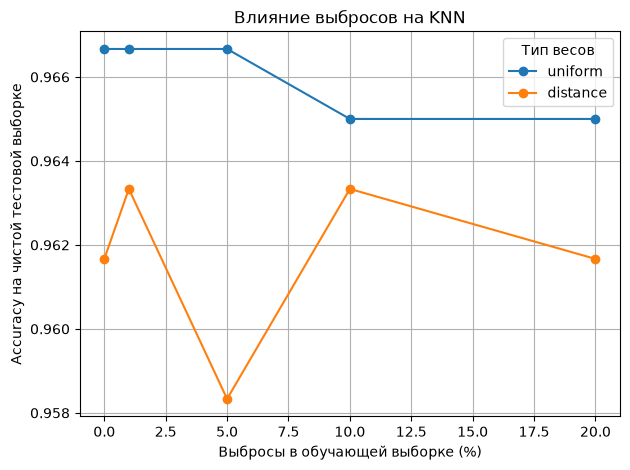

In [23]:
# При uniform каждый сосед голосует одинаково, а при distance ближайшие точки имеют больший вес. 
# Поэтому близкий шумный объект может сильнее повлиять на взвешенную модель. distance не всегда хуже: устойчивость зависит от того, где расположены выбросы.


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

# 1. Создаём двумерный набор данных
X, y = make_moons(
    n_samples=2000,
    noise=0.20,
    random_state=42
)

# 2. Разделяем данные на обучение и тест
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Масштабируем по обучающей выборке
scaler = StandardScaler()
X_train_clean = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# 4. Функция добавления выбросов в обучающие признаки
def add_outliers(X, fraction, seed=42):
    rng = np.random.default_rng(seed)
    X_noisy = X.copy()

    n_outliers = int(len(X) * fraction)
    indices = rng.choice(len(X), n_outliers, replace=False)

    # Сильно сдвигаем выбранные объекты в пространстве признаков
    X_noisy[indices] += rng.normal(
        loc=0,
        scale=4,
        size=(n_outliers, X.shape[1])
    )

    return X_noisy

# 5. Проверяем разную долю выбросов
outlier_fractions = [0.00, 0.01, 0.05, 0.10, 0.20]
results = []

for fraction in outlier_fractions:
    X_train_noisy = add_outliers(
        X_train_clean,
        fraction,
        seed=42
    )

    for weights in ["uniform", "distance"]:
        model = KNeighborsClassifier(
            n_neighbors=7,
            weights=weights
        )

        model.fit(X_train_noisy, y_train)
        y_pred = model.predict(X_test)

        results.append({
            "Outlier_fraction": fraction,
            "Weights": weights,
            "Accuracy": accuracy_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred)
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

# 6. Строим график зависимости Accuracy от доли выбросов
for weights in ["uniform", "distance"]:
    subset = results_df[results_df["Weights"] == weights]

    plt.plot(
        subset["Outlier_fraction"] * 100,
        subset["Accuracy"],
        marker="o",
        label=weights
    )

plt.xlabel("Выбросы в обучающей выборке (%)")
plt.ylabel("Accuracy на чистой тестовой выборке")
plt.title("Влияние выбросов на KNN")
plt.legend(title="Тип весов")
plt.grid(True)
plt.tight_layout()
plt.show()


### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

 Noise_features  Total_features  Accuracy     F1  Recall
              0              15    0.9020 0.5051  0.3538
              5              20    0.8747 0.2419  0.1415
             20              35    0.8580 0.1162  0.0660
             50              65    0.8520 0.0513  0.0283
            100             115    0.8513 0.0429  0.0236


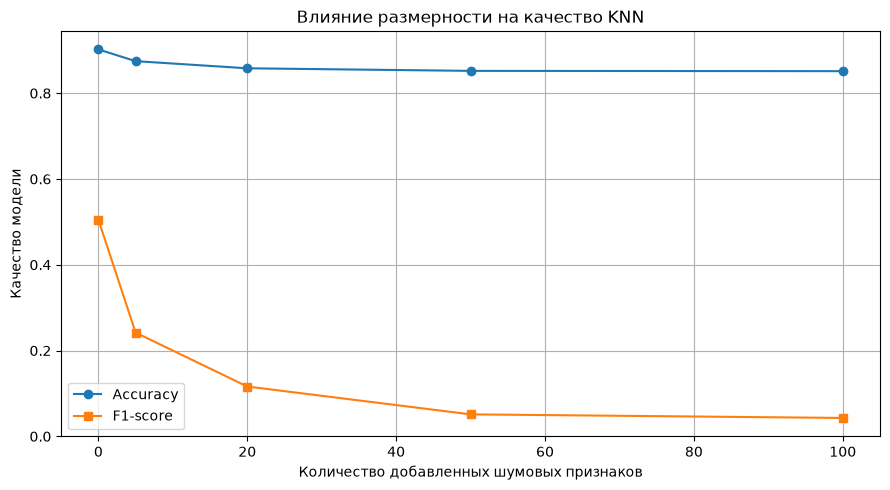

In [24]:
#KNN принимает решения на основе расстояний между объектами. Я добавил к исходным данным случайные признаки, не связанные с оттоком клиентов, и проверил качество при разной размерности.
#Шумовые признаки могут искажать расстояния и ухудшать выбор ближайших соседей. Поэтому в машинном обучении важно не просто увеличивать число признаков, а выбирать информативные




import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

# 1. Загружаем данные Orange Telecom Churn
df = pd.read_csv("Orange_Telecom_Churn_Data.csv")

# 2. Подготавливаем целевую переменную
y = df["churned"]

if y.dtype == "object":
    y = y.astype(str).str.strip().str.lower().map({
        "true": 1, "false": 0,
        "yes": 1, "no": 0,
        "1": 1, "0": 0
    })

valid = y.notna()
df = df.loc[valid].reset_index(drop=True)
y = y.loc[valid].astype(int).to_numpy()

# 3. Берём числовые признаки, исключая цель и идентификаторы
drop_cols = ["churned", "phone_number", "area_code"]
X_df = df.drop(columns=drop_cols, errors="ignore")
X_df = X_df.select_dtypes(include=np.number)

# Удаляем колонки, полностью состоящие из пропусков
X_df = X_df.dropna(axis=1, how="all")

# 4. Делим данные до масштабирования
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_df, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 5. Заполняем пропуски и масштабируем
imputer = SimpleImputer(strategy="median")
scaler = MinMaxScaler()

X_train = imputer.fit_transform(X_train_df)
X_test = imputer.transform(X_test_df)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 6. Сравниваем модели с разным количеством шумовых признаков
noise_counts = [0, 5, 20, 50, 100]
results = []

rng = np.random.default_rng(42)

for n_noise in noise_counts:
    if n_noise == 0:
        X_train_exp = X_train.copy()
        X_test_exp = X_test.copy()
    else:
        # Независимый случайный шум для train и test
        noise_train = rng.uniform(
            0, 1, size=(len(X_train), n_noise)
        )
        noise_test = rng.uniform(
            0, 1, size=(len(X_test), n_noise)
        )

        X_train_exp = np.hstack([X_train, noise_train])
        X_test_exp = np.hstack([X_test, noise_test])

    # Обучаем KNN
    model = KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="euclidean"
    )
    model.fit(X_train_exp, y_train)

    # Оцениваем на тестовой выборке
    y_pred = model.predict(X_test_exp)

    results.append({
        "Noise_features": n_noise,
        "Total_features": X_train_exp.shape[1],
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

# 7. Строим график качества
plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Noise_features"],
    results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)
plt.plot(
    results_df["Noise_features"],
    results_df["F1"],
    marker="s",
    label="F1-score"
)

plt.xlabel("Количество добавленных шумовых признаков")
plt.ylabel("Качество модели")
plt.title("Влияние размерности на качество KNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Упражнение 11: KNN для регрессии против классификации
Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE — Mean Squared Error) для различных значений K.

Колонки датасета:
['state', 'account_length', 'area_code', 'phone_number', 'intl_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_calls', 'total_day_charge', 'total_eve_minutes', 'total_eve_calls', 'total_eve_charge', 'total_night_minutes', 'total_night_calls', 'total_night_charge', 'total_intl_minutes', 'total_intl_calls', 'total_intl_charge', 'number_customer_service_calls', 'churned']

Признаки: ['total_day_minutes', 'total_day_calls']
Целевая переменная: total_day_charge
Количество объектов: 5000

Результаты:
 K    MSE   RMSE
 1 1.1929 1.0922
 2 0.9373 0.9681
 3 1.0097 1.0049
 4 0.7781 0.8821
 5 0.6419 0.8012
 6 0.6329 0.7956
 7 0.7237 0.8507
 8 0.6842 0.8272
 9 0.6457 0.8036
10 0.6777 0.8232
11 0.7070 0.8408
12 0.7477 0.8647
13 0.8116 0.9009
14 0.8441 0.9188
15 0.8732 0.9344
16 0.8666 0.9309
17 0.8828 0.9396
18 0.8970 0.9471
19 0.8813 0.9388
20 0.9144 0.9563
21 0.9216 0.9600
22 0.9264 0.9625
23 0.9657 0.9827
24 0.9703 0.9850
25 0.9969 0.9984
26 1.

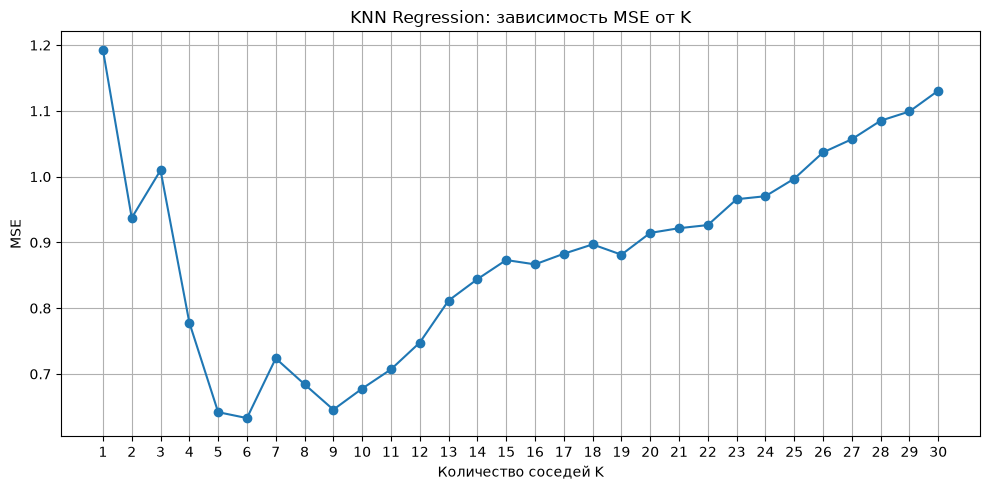

In [25]:
#алгоритм KNeighborsRegressor был применён для прогнозирования непрерывной переменной total_day_charge на основе характеристик дневных звонков клиента.

#Для выбора количества ближайших соседей были протестированы значения K от 1 до 30. Качество регрессии оценивалось с помощью средней квадратичной ошибки MSE.
#Для каждого значения K модель обучалась на тренировочной выборке, а ошибка вычислялась на отдельной тестовой выборке.

#Оптимальным считалось значение K, при котором MSE на тестовой выборке минимальна. Эксперимент показывает, что выбор числа соседей влияет на точность регрессионного прогноза.
#При малом K модель может быть чувствительна к отдельным объектам, а при слишком большом K прогноз может стать чрезмерно сглаженным.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

# 1. Загружаем данные
df = pd.read_csv("Orange_Telecom_Churn_Data.csv")

# Проверяем названия колонок
print("Колонки датасета:")
print(df.columns.tolist())

# 2. Выбираем целевую переменную
target_candidates = ["total_day_charge", "total_day_charges"]
target_col = next(
    (col for col in target_candidates if col in df.columns),
    None
)

if target_col is None:
    raise ValueError(
        "Не найдена колонка total_day_charge или total_day_charges. "
        "Проверь названия колонок."
    )

# 3. Выбираем признаки для предсказания расходов
feature_candidates = [
    "total_day_minutes",
    "total_day_calls"
]

feature_cols = [
    col for col in feature_candidates if col in df.columns
]

if not feature_cols:
    raise ValueError(
        "Не найдены признаки total_day_minutes и total_day_calls."
    )

# Оставляем только нужные столбцы
data = df[feature_cols + [target_col]].copy()

# Преобразуем значения в числа
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Удаляем строки без известного целевого значения
data = data.dropna(subset=[target_col])

X = data[feature_cols]
y = data[target_col]

print("\nПризнаки:", feature_cols)
print("Целевая переменная:", target_col)
print("Количество объектов:", len(data))

# 4. Разделяем данные на обучение и тест
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# 5. Подготавливаем данные
# Импутация и масштабирование обучаются только на train
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# 6. Проверяем разные значения K
results = []

for k in range(1, 31):
    model = KNeighborsRegressor(
        n_neighbors=k,
        weights="uniform"
    )

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    mse = mean_squared_error(y_test, y_pred)

    results.append({
        "K": k,
        "MSE": mse,
        "RMSE": np.sqrt(mse)
    })

results_df = pd.DataFrame(results)

# 7. Выводим результаты
print("\nРезультаты:")
print(results_df.round(4).to_string(index=False))

# 8. Находим K с минимальной тестовой ошибкой
best_row = results_df.loc[results_df["MSE"].idxmin()]

print("\nОптимальное K:", int(best_row["K"]))
print("Минимальный MSE:", round(best_row["MSE"], 4))
print("RMSE:", round(best_row["RMSE"], 4))

# 9. Строим график MSE
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["K"],
    results_df["MSE"],
    marker="o"
)

plt.xticks(range(1, 31))
plt.xlabel("Количество соседей K")
plt.ylabel("MSE")
plt.title("KNN Regression: зависимость MSE от K")
plt.grid(True)
plt.tight_layout()
plt.show()

#


### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [26]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Загружаем данные
df = pd.read_csv("Orange_Telecom_Churn_Data.csv")

# 2. Проверяем, что целевая переменная существует
target = "churned"

if target not in df.columns:
    raise ValueError(
        f"Столбец '{target}' не найден. Доступные столбцы: {list(df.columns)}"
    )

# 3. Подготавливаем целевую переменную
y = df[target]

# Если значения записаны текстом, преобразуем их в 0 и 1
if y.dtype == "object":
    y = y.astype(str).str.strip().str.lower().map({
        "true": 1,
        "false": 0,
        "yes": 1,
        "no": 0,
        "1": 1,
        "0": 0
    })
else:
    # Поддерживаем также булевы значения True/False
    y = y.map({True: 1, False: 0}) if y.dtype == bool else y

# Удаляем строки, в которых целевая переменная не распознана
valid_rows = y.notna()
df = df.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

# 4. Удаляем целевую переменную из признаков
X = df.drop(columns=[target])

# Убираем идентификаторы, которые обычно не помогают предсказывать отток
id_columns = [
    col for col in ["state", "area_code", "phone_number"]
    if col in X.columns
]
X = X.drop(columns=id_columns)

# Преобразуем категориальные признаки в числовые
X = pd.get_dummies(X, drop_first=False, dtype=int)

# Удаляем бесконечные значения, если они есть
X = X.replace([np.inf, -np.inf], np.nan)

print("Размер X:", X.shape)
print("Распределение целевого класса:")
print(y.value_counts())

# 5. Разделяем данные на обучение и тест
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Строим Pipeline
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("knn", KNeighborsClassifier())
])

# 7. Настраиваем сетку гиперпараметров
# 'all' означает использовать все признаки.
# Числовые варианты добавляются только тогда, когда они допустимы.
n_features = X_train.shape[1]

k_features = ["all"]
for k in [5, 10, 15]:
    if k < n_features:
        k_features.append(k)

param_grid = {
    "select__k": k_features,
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

# 8. Запускаем поиск с 5-fold кросс-валидацией
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

# 9. Выводим лучшие параметры
print("\nЛучшие параметры:")
print(grid_search.best_params_)

print("\nЛучшая средняя accuracy на кросс-валидации:")
print(round(grid_search.best_score_, 4))

# 10. Оцениваем лучшую модель на тестовой выборке
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy на тестовой выборке:")
print(round(test_accuracy, 4))

print("\nМатрица ошибок:")
print(confusion_matrix(y_test, y_pred))

print("\nОтчёт по классификации:")
print(classification_report(y_test, y_pred, zero_division=0))


Размер X: (5000, 19)
Распределение целевого класса:
churned
0    4293
1     707
Name: count, dtype: int64
Fitting 5 folds for each of 80 candidates, totalling 400 fits

Лучшие параметры:
{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'distance', 'select__k': 15}

Лучшая средняя accuracy на кросс-валидации:
0.9175

Accuracy на тестовой выборке:
0.923

Матрица ошибок:
[[847  12]
 [ 65  76]]

Отчёт по классификации:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96       859
           1       0.86      0.54      0.66       141

    accuracy                           0.92      1000
   macro avg       0.90      0.76      0.81      1000
weighted avg       0.92      0.92      0.92      1000

